# 5 Random Forest

## 5.1 Requirements


In [81]:
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    precision_recall_curve, average_precision_score, recall_score, precision_score, f1_score)
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
SEED = 42
FAST = os.environ.get("FAST", "0") == "1"   # FAST=1 shrinks everything for a quick smoke test
NJ = -1

## 5.2 Data

In [82]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


In [83]:
import io, base64
from IPython.display import display, HTML

ys = {"train": y_tr, "val": y_va}   # target arrays per split (test deliberately excluded)

_KEYS = {"train": ("p_tr", "sc_tr"), "val": ("p_va", "sc_va")}

def _probs(m, split):
    p_key, sc_key = _KEYS[split]          # KeyError if someone asks for "test"
    if p_key in m:
        return np.asarray(m[p_key])
    return m["platt"].predict_proba(np.asarray(m[sc_key]).reshape(-1, 1))[:, 1]

def _grid(n, ncols=2, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p = _probs(m, split)
        fpr, tpr, _ = roc_curve(ys[split], p)
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p_, r_, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r_, p_, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="val", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_score_distribution(models, ys=ys, split="val", bins=40):
    sc_key = _KEYS[split][1]
    fig, axs = _grid(len(models)); y = np.asarray(ys[split])
    for ax, (n, m) in zip(axs, models.items()):
        sc = np.asarray(m[sc_key]); lo, hi = np.percentile(sc, [0.5, 99.5])
        ax.hist(sc[y == 0], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="non-default")
        ax.hist(sc[y == 1], bins=bins, range=(lo, hi), alpha=0.6, density=True, label="default")
        ax.set_title(n); ax.set_xlabel("LLR score"); ax.legend()
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Score distribution by class ({split})"); plt.tight_layout(); plt.show()

def best_threshold(m, y_val, y_split="val"):
    fpr, tpr, thr = roc_curve(y_val, _probs(m, y_split))
    return thr[np.argmax(tpr - fpr)]

def plot_confusion(models, ys=ys, split="val", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

def show_row(*calls, width=330):
    imgs, _show = [], plt.show
    plt.show = lambda *a, **k: None
    try:
        for call in calls:
            call()
            fig = plt.gcf()
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
            plt.close(fig)
            imgs.append(base64.b64encode(buf.getvalue()).decode())
    finally:
        plt.show = _show
    html = "".join(f"<img src='data:image/png;base64,{b}' style='width:{width}px'>" for b in imgs)
    display(HTML(f"<div style='display:flex;flex-wrap:wrap;gap:8px'>{html}</div>"))

## 5.3 Motivations

Another model we thought could be applied to our problem is a Random Forest. We suspect that this could be a useful model to apply to this binary classification problem for these reasons:
- Variance of the model is cut by utilising many trees while taking advantage of their low bias,
- It captures non linear interactions in data without manually specifying the pattern
- Diagnostics are built into the model, for example out of bag errors

There are also challenges we will have to tackle when implementing this model some examples are:
- Class imbalance can cause bias towards majority class
- More diffcult to interpret
- Poor when extrapolating out of training data range

## 5.4 How does a random forest work?

A random forest is made using many decision trees. Each of the trees are trained on a different portion of the features of the tree and their predictions are averaged.

**Decision Tree**

For a single decision tree each covaritate is split at a threshold to best classify default or not default. For example "latest payment status $\le 0$. After getting to the bottom of the tree each leaf has a probability of defaulting. When a new client is then passed through it will end up at a leaf and depeding on the final threshold will be predicted as default or non-default. A single tree has problems of extreme variance and overfitting, but by pruning and utilisng a random forest instead these can be limited.

**Building the forest.** A forest of $B$ trees is built in three steps:

1. **Bootstrap sampling.** For each tree, draw $n$ rows with replacement from the $n$ training rows. Each tree will see a slightly different version of the data, with some rows repeated and left out.
2. **Random feature subsets.** At every split, the tree does not search all the features. It looks at a random subset of `max_features` of them (by default $\sqrt{p}$ in scikit-learn for classification) and picks the best split among those. Without this step, a few strong features would dominate the top splits of every tree, making the trees too similar.
3. **Grow each tree deeply.** Each tree is grown with little pruning, controlled by settings such as `min_samples_leaf` and `max_depth`. Individual trees are overfitted, noisy models, which is acceptable because the averaging step removes much of that noise.

because each tree leaves out about a third of the rows, every row has trees that never saw it. Scoring each row with those trees alone gives the **out-of-bag** estimate of performance. The forest also provides feature importances, which we compare against permutation importance in Section 12.

## 5.5 Baseline Model

### 5.5.1 Builidng the Model

For an inital model we will create a simple forest using all of the columns. This way as we make changes we can assess if our changes have made a positive impact on the model, or in the case of simplifying data if the losses are negligible enough to justify removal. 

In [84]:
#takes the raw features and trains a baseline RF model to compare against the Markov models
raw_cols = [c for c in train.columns if c != TARGET]
#feature matrix
Xr_tr, Xr_va, Xr_te = train[raw_cols], validation[raw_cols], test[raw_cols]

#baseline evaluation function for the raw features
def evaluate(p, y):
    return {"AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
            "LogLoss": log_loss(y, np.clip(p,1e-6,1-1e-6)), "Brier": brier_score_loss(y, p)
            }

#fit the rf
rf0 = RandomForestClassifier(n_estimators=100 if FAST else 300, min_samples_leaf=1, n_jobs=NJ, random_state=SEED, oob_score=True)
rf0.fit(Xr_tr, y_tr)
#score the rf on the validation set and print the results
base = {"val": evaluate(rf0.predict_proba(Xr_va)[:,1], y_va), "OOB accuracy": rf0.oob_score_}
print(pd.DataFrame(base["val"], index=["baseline RF (raw)"]).round(4)); print("OOB accuracy:", round(rf0.oob_score_,4))
print("Majority-class accuracy:", round(1-y_va.mean(),4))

thr = 0.3  
pred = (rf0.predict_proba(Xr_va)[:, 1] >= thr).astype(int)
cm = confusion_matrix(y_va, pred)
print(pd.DataFrame(cm, index=["true 0", "true 1"], columns=["pred 0", "pred 1"]))
print("Recall (defaulters caught):", round(cm[1, 1] / cm[1].sum(), 3),
      "| Precision:", round(cm[1, 1] / max(cm[:, 1].sum(), 1), 3))



                      AUC      AP  LogLoss  Brier
baseline RF (raw)  0.7647  0.5485   0.4388  0.137
OOB accuracy: 0.8154
Majority-class accuracy: 0.7788
        pred 0  pred 1
true 0    3956     716
true 1     588     739
Recall (defaulters caught): 0.557 | Precision: 0.508


These inital results are promising for a baseline model the accuracy is higher than assigning majority class blankly and the other performance metrics arent worrying. The confusion matrix initially showed strong bias for the majority class but after messing with the threshold it was able to give a decent recall.


### 5.5.2 Numerical Checks


In [85]:
# (a) Gini and split gain: worked example on the strongest raw predictor
def gini(y): p = np.mean(y); return 2*p*(1-p)
def best_split(x, y):
    xs = np.unique(np.quantile(x, np.linspace(.02,.98,49)))
    gains = []
    for t in xs:
        L = x <= t; nL = L.sum()
        gains.append(gini(y) - nL/len(y)*gini(y[L]) - (1-nL/len(y))*gini(y[~L]))
    i = int(np.argmax(gains)); return xs[i], gains[i]
for c in ["PAY_1", "LIMIT_BAL", "AGE"]:
    t, g = best_split(train[c].values, y_tr); print(f"{c:10s} best threshold {t:>10.1f}  gain {g:.5f}")
print("Parent Gini:", round(gini(y_tr),4))

# (b) bootstrap: fraction of rows in-bag
rng = np.random.default_rng(SEED); n = len(y_tr)
inbag = [len(np.unique(rng.integers(0, n, n)))/n for _ in range(50)]
print("Mean in-bag fraction:", round(np.mean(inbag),4), " theory 1-1/e =", round(1-np.exp(-1),4))

PAY_1      best threshold        1.0  gain 0.05207
LIMIT_BAL  best threshold   120000.0  gain 0.00826
AGE        best threshold       24.0  gain 0.00080
Parent Gini: 0.3445
Mean in-bag fraction: 0.6326  theory 1-1/e = 0.6321


## 5.6 Feature engineering

### 5.6.2 Feature Choices

In [86]:
def make_features(d):
    X = d.drop(columns=TARGET).copy(); L = X["LIMIT_BAL"]
    B, A = X[bill_cols].values, X[amt_cols].values
    X["n_late"]      = (X[pay_cols] > 0).sum(axis=1)
    X["max_delay"]   = X[pay_cols].max(axis=1)
    X["mean_pay"]    = X[pay_cols].mean(axis=1)
    X["recent_late"] = (X[["PAY_1", "PAY_2"]] > 0).sum(axis=1)
    X["n_revolve"]   = (X[pay_cols] == 0).sum(axis=1)
    X["pay_slope"]   = X["PAY_1"] - X["PAY_6"]
    X["util_1"]      = B[:, -1] / L
    X["util_mean"]   = B.mean(axis=1) / L
    X["util_max"]    = B.max(axis=1) / L
    X["bill_trend"]  = (B[:, -1] - B[:, 0]) / L
    X["repay_ratio"] = A.sum(axis=1) / (np.clip(B, 0, None).sum(axis=1) + 1)
    X["zero_pay_n"]  = (A == 0).sum(axis=1)
    X["bill_vol"]    = B.std(axis=1) / (np.abs(B).mean(axis=1) + 1)
    return X
X_tr, X_va, X_te = make_features(train), make_features(validation), make_features(test)



### 5.6.2 New Models

In [87]:

models = {
    "RF": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "HGB": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=200,
                                          l2_regularization=1, random_state=42),
}
for m in models.values(): m.fit(X_tr, y_tr)

### 5.6.3 Tuning and Calibration

In [88]:
import time, joblib
from scipy.stats import randint, loguniform
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

SEED = 42
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # 3 folds 

# --- RF: search with fewer, cheaper trees, then refit the winner with more trees ---
rf_space = {"min_samples_leaf": randint(5, 80),
            "max_features": ["sqrt", 0.2, 0.35],
            "max_depth": [None, 12, 18],
            "max_samples": [0.5, 0.7]}            # smaller bootstrap = faster trees
t0 = time.time()
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=SEED),
    rf_space, n_iter=10, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED, verbose=1,
).fit(X_tr, y_tr)
print(f"RF search: {time.time()-t0:.0f}s  CV AUC {rf_search.best_score_:.4f}  {rf_search.best_params_}")

# --- HGB: usually fast; early stopping removes the need to tune max_iter ---
hgb_space = {"learning_rate": loguniform(0.02, 0.2),
             "max_depth": [3, 4, 5, None],
             "max_leaf_nodes": randint(8, 40),
             "min_samples_leaf": randint(20, 200),
             "l2_regularization": loguniform(1e-2, 1e2)}

t0 = time.time()
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(max_iter=500, early_stopping=True, n_iter_no_change=15, random_state=SEED),
    hgb_space, n_iter=15, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=SEED, verbose=1,
).fit(X_tr, y_tr)
print(f"HGB search: {time.time()-t0:.0f}s  CV AUC {hgb_search.best_score_:.4f}  {hgb_search.best_params_}")

# final RF with more trees and all cores
rf_best  = RandomForestClassifier(**{**rf_search.best_params_, "n_estimators": 500, "n_jobs": -1, "random_state": SEED}).fit(X_tr, y_tr)
hgb_best = hgb_search.best_estimator_
joblib.dump({"rf": rf_best, "hgb": hgb_best}, "tuned_models.joblib")   # so you never have to rerun this

Fitting 3 folds for each of 10 candidates, totalling 30 fits
RF search: 18s  CV AUC 0.7805  {'max_depth': 12, 'max_features': 0.35, 'max_samples': 0.7, 'min_samples_leaf': 59}
Fitting 3 folds for each of 15 candidates, totalling 45 fits
HGB search: 3s  CV AUC 0.7816  {'l2_regularization': np.float64(1.7912362571043667), 'learning_rate': np.float64(0.04857876818821363), 'max_depth': 4, 'max_leaf_nodes': 28, 'min_samples_leaf': 149}


['tuned_models.joblib']

## 5.7 Comparison

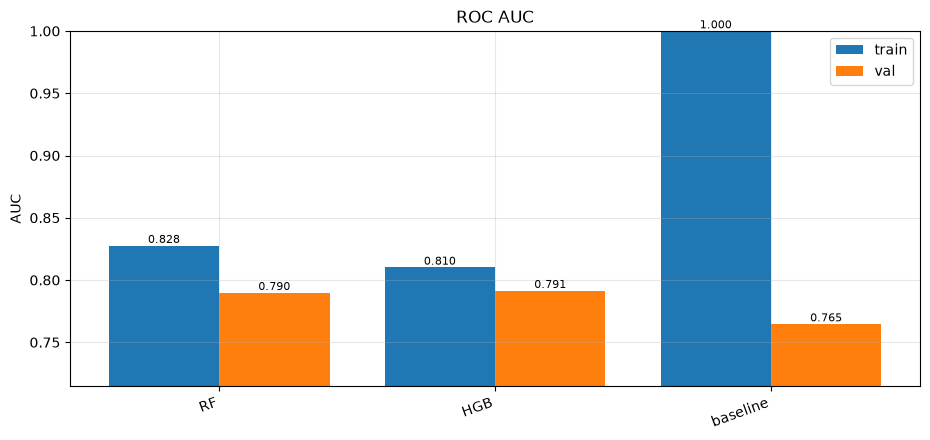

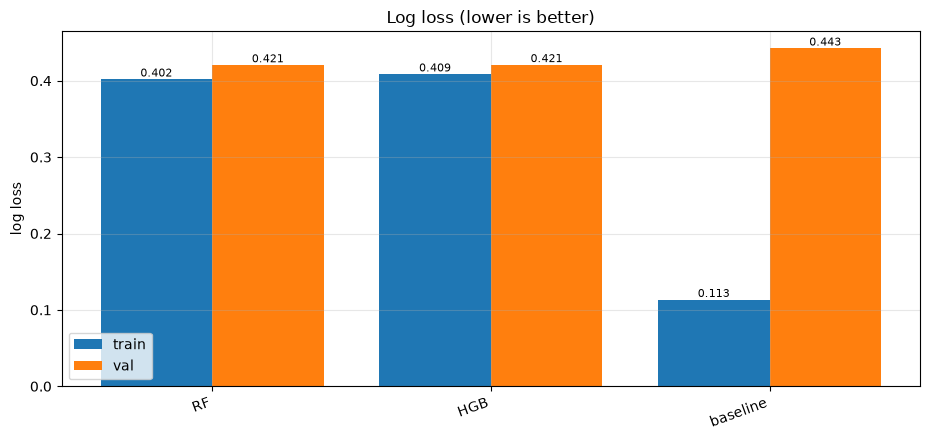

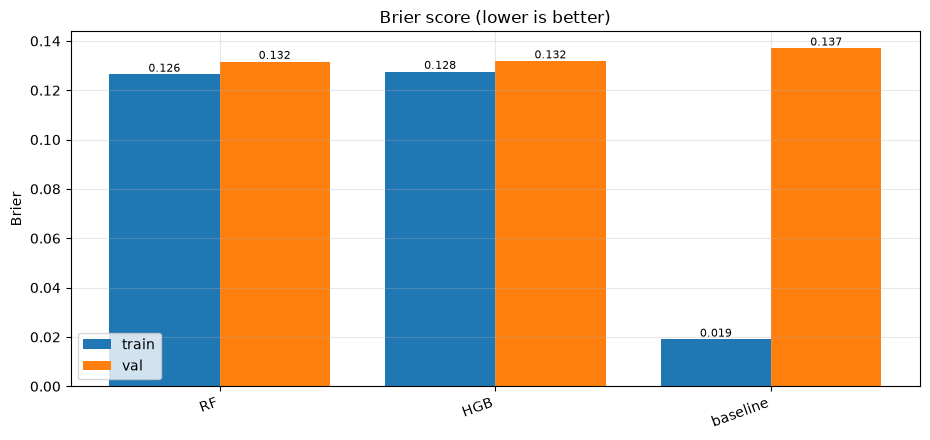

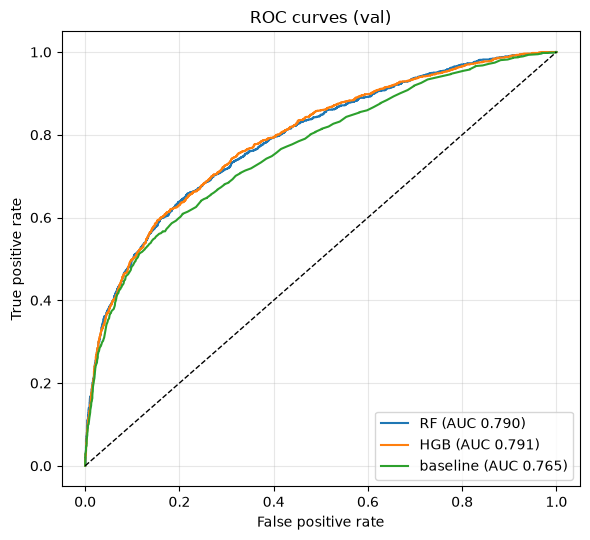

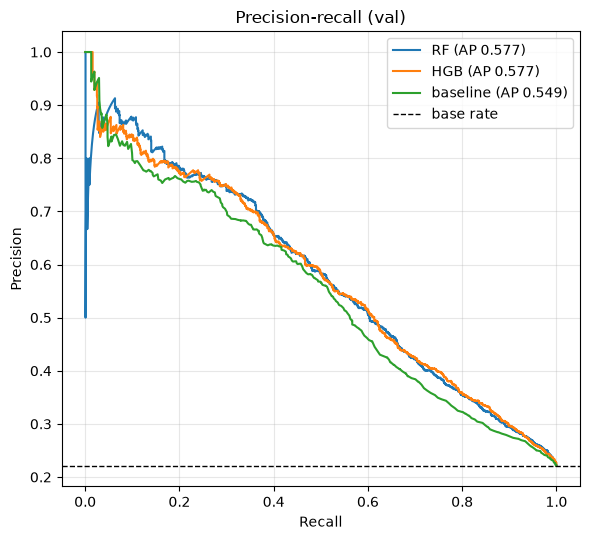

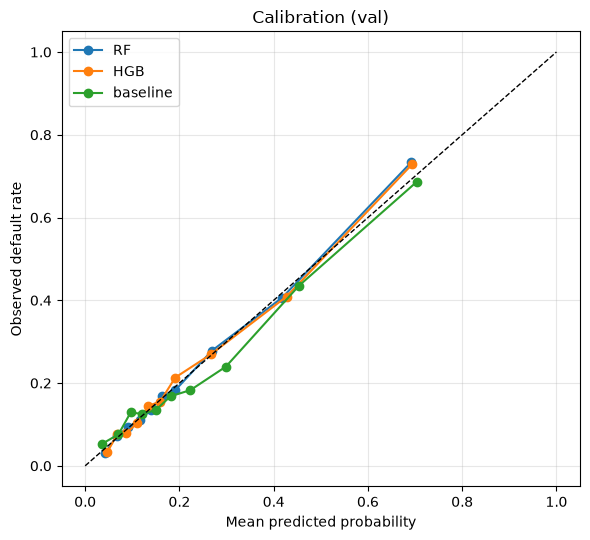

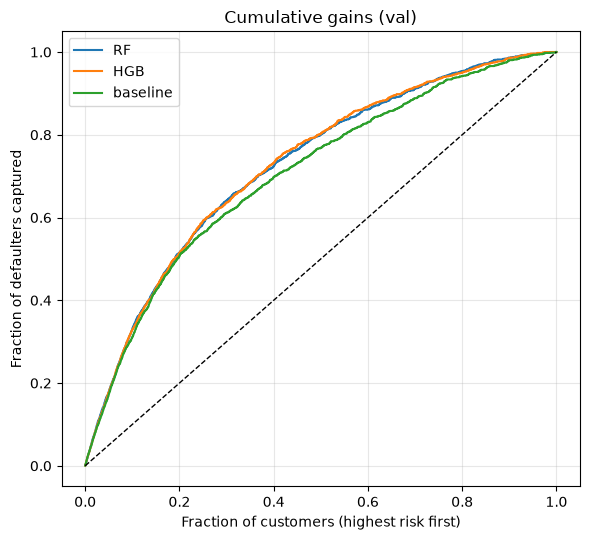

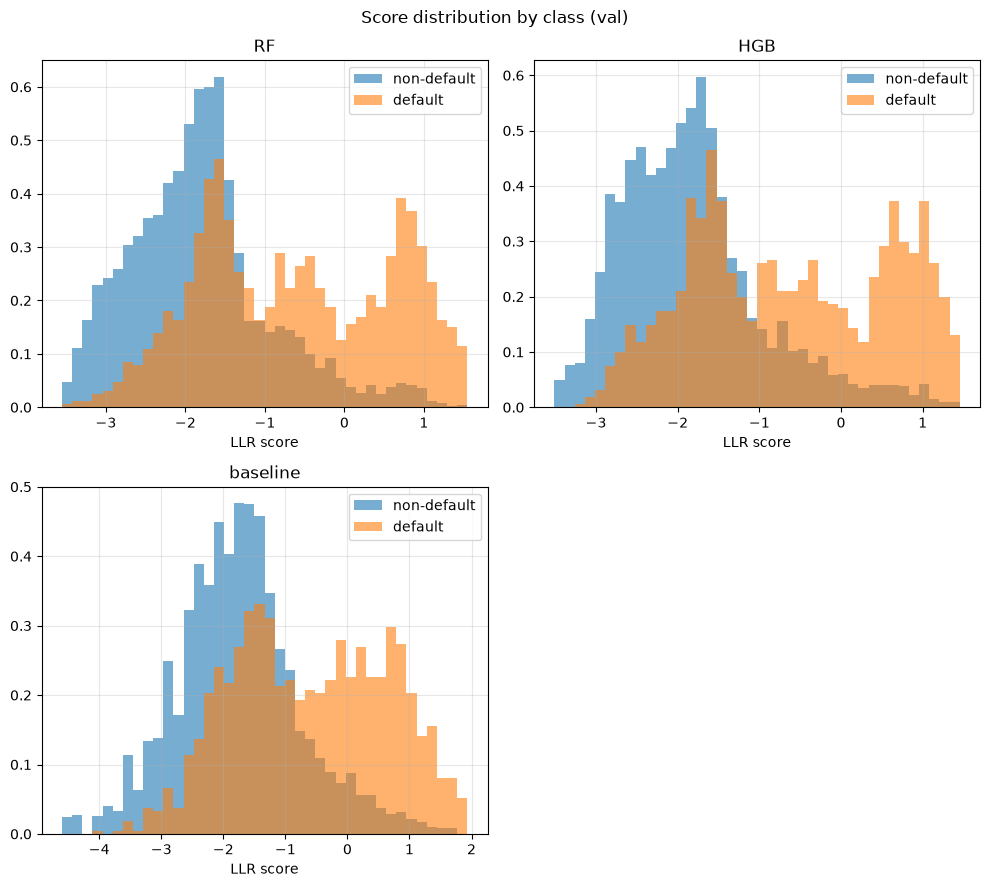

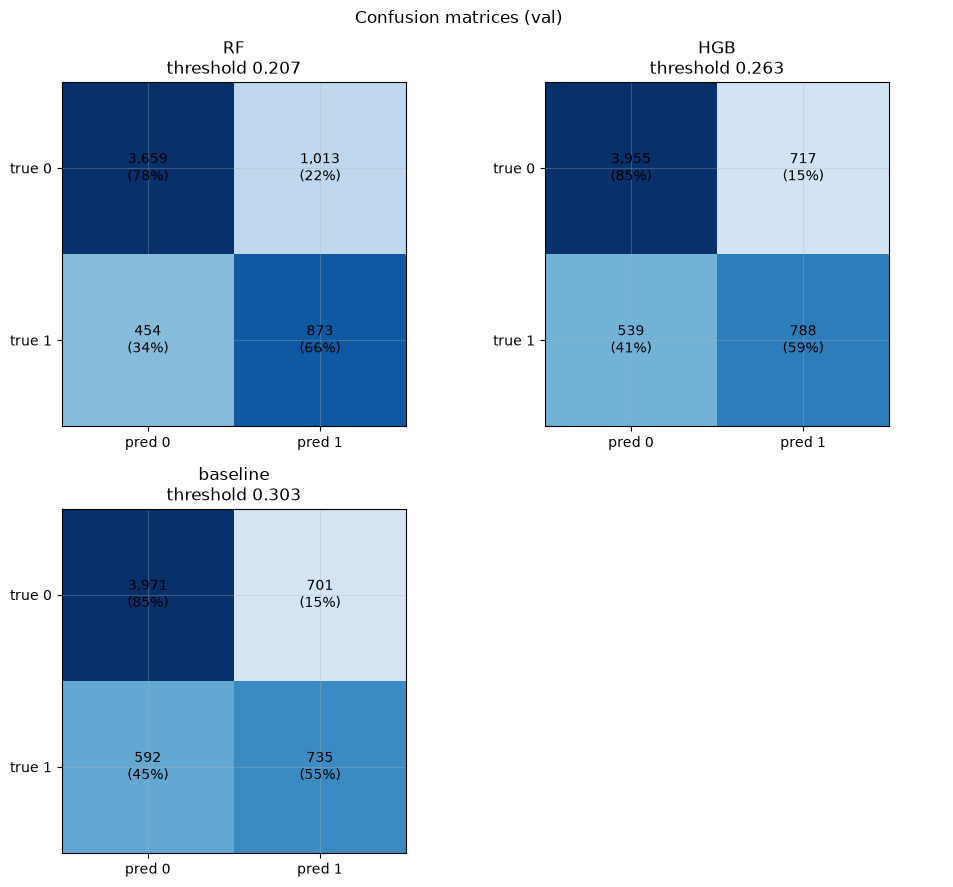

In [89]:
models = {"RF": rf_best, "HGB": hgb_best, "baseline": rf0}

def as_result(model, eps=1e-6):
    out = {}
    for tag, X_full in [("tr", X_tr), ("va", X_va)]:
        X = X_full[model.feature_names_in_]          # use exactly the columns this model was trained on
        p = model.predict_proba(X)[:, 1]
        out[f"p_{tag}"] = p
        pc = np.clip(p, eps, 1 - eps)
        out[f"sc_{tag}"] = np.log(pc / (1 - pc))      # log-odds, used by plot_score_distribution
    return out

results = {name: as_result(m) for name, m in models.items()}

auc_vals   = plot_auc(results)
ll_vals    = plot_logloss(results)
brier_vals = plot_brier(results)

plot_roc(results, split="val")
plot_pr(results, split="val")
plot_calibration(results, split="val")
plot_gains(results, split="val")
plot_score_distribution(results, split="val")
plot_confusion(results, split="val")
 

## 5.8 Conclusion

HGB model the best final model for random forest
